In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
from pipeline.notebook_utils import (
    carregar_noaa_por_tipo,
    identificar_porcoes_ativas,
    processar_ou_carregar_porcao,
    media_por_sink_raio,
    ajustar_lei_potencia,
    plotar_lei_potencia,
    plotar_varredura_4_tipos_r1_a_22km,
)

tipos_noaa = carregar_noaa_por_tipo()
for nome, df_t in tipos_noaa.items():
    print(f"{nome:16s}: {len(df_t):5d} pontos")

Ocean water     : 14363 pontos
Ocean sediment  :   319 pontos
Nurdle Patrol   : 10615 pontos
Beach           :   893 pontos


In [2]:
info, arr, label, porcoes_ativas = identificar_porcoes_ativas(tipos_noaa["Ocean water"], max_r_km=50.0)

bacias_por_porcao = [processar_ou_carregar_porcao(v, info, arr, label) for v in porcoes_ativas]
df_bacias_globais = pd.concat([d for d in bacias_por_porcao if len(d) > 0], ignore_index=True)
df_bacias_principais = df_bacias_globais[df_bacias_globais["area_km2"] >= 100.0].reset_index(drop=True)
print(f"Porcoes ativas: {len(porcoes_ativas)} | Bacias >= 100 km2: {len(df_bacias_principais)}")

Porcoes ativas: 1061 | Bacias >= 100 km2: 20168


In [3]:
pareados_tipos_r = {nome: {} for nome in tipos_noaa}
linhas_tipos = []

for nome, pts_df in tipos_noaa.items():
    for r_km in range(1, 23):
        df_r = media_por_sink_raio(df_bacias_principais, pts_df, r_km=r_km)
        pareados_tipos_r[nome][r_km] = df_r
        c_u = ajustar_lei_potencia(df_r, "urban_population", "mp_mean")
        f_t = ajustar_lei_potencia(df_r, "total_population", "flux")
        linhas_tipos.append({
            "Tipo_NOAA": nome,
            "R_km": r_km,
            "N_urb": c_u["N"],
            "beta_Conc_Urb": c_u["beta"],
            "R2_Conc_Urb_pct": c_u["r2_pct"],
            "N_tot": f_t["N"],
            "beta_Fluxo_Tot": f_t["beta"],
            "R2_Fluxo_Tot_pct": f_t["r2_pct"],
        })

df_var_tipos = pd.DataFrame(linhas_tipos)
print(df_var_tipos[df_var_tipos["R_km"].isin([5, 10, 13, 18, 22])].round(2).to_string(index=False))

     Tipo_NOAA  R_km  N_urb  beta_Conc_Urb  R2_Conc_Urb_pct  N_tot  beta_Fluxo_Tot  R2_Fluxo_Tot_pct
   Ocean water     5     49           0.70            33.27     65            0.81             34.55
   Ocean water    10    117           0.50            11.85    199            0.74             27.27
   Ocean water    13    157           0.52            13.30    300            0.63             26.03
   Ocean water    18    242           0.44            11.28    463            0.56             25.65
   Ocean water    22    314           0.37             7.93    624            0.52             25.27
Ocean sediment     5      9           0.34            83.92     14            0.31              8.04
Ocean sediment    10     17           0.40            30.79     33            0.85             50.98
Ocean sediment    13     22           0.28            16.81     44            0.68             42.00
Ocean sediment    18     36           0.28            16.89     67            0.75         

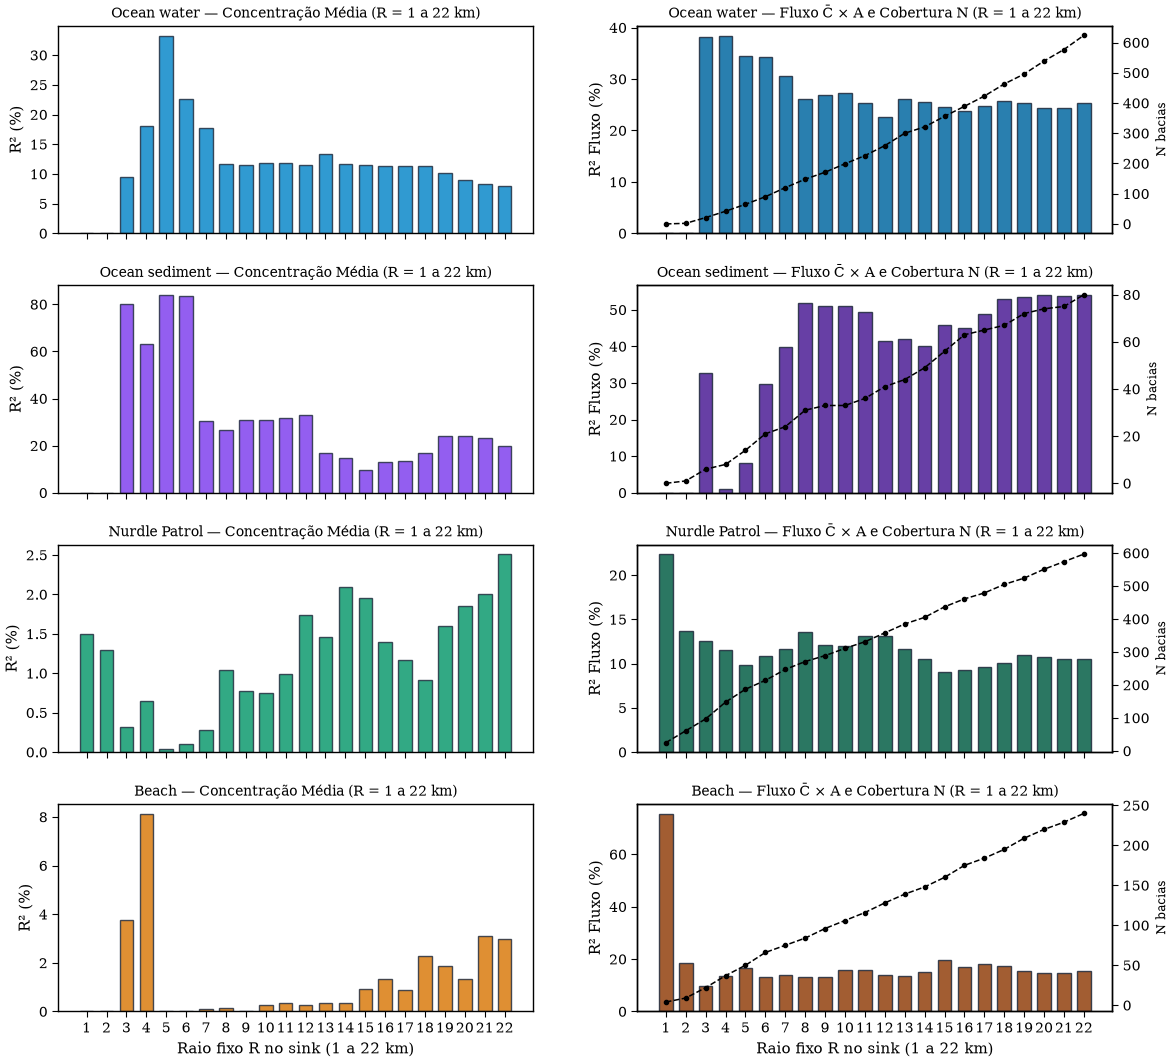

In [4]:
plotar_varredura_4_tipos_r1_a_22km(df_var_tipos)

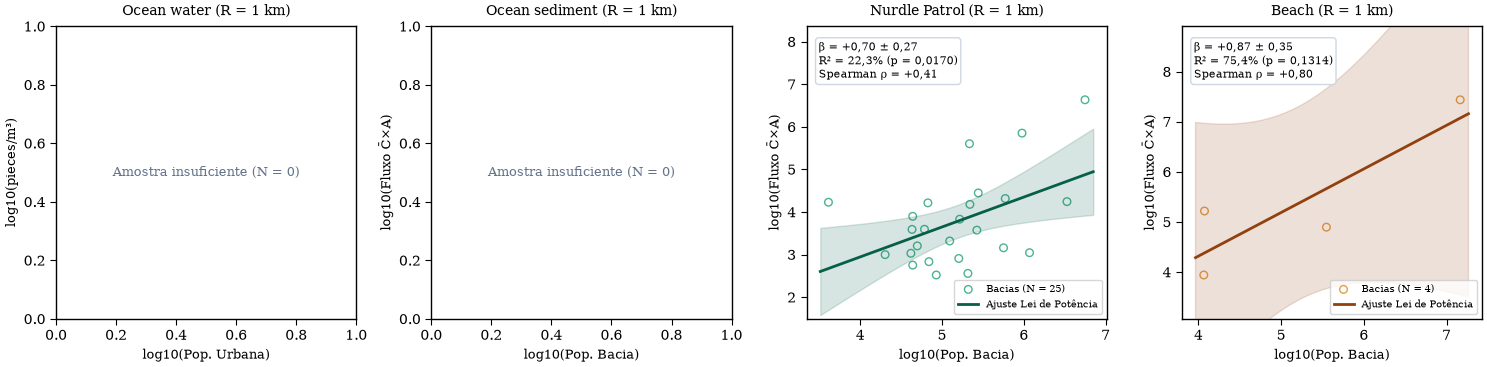

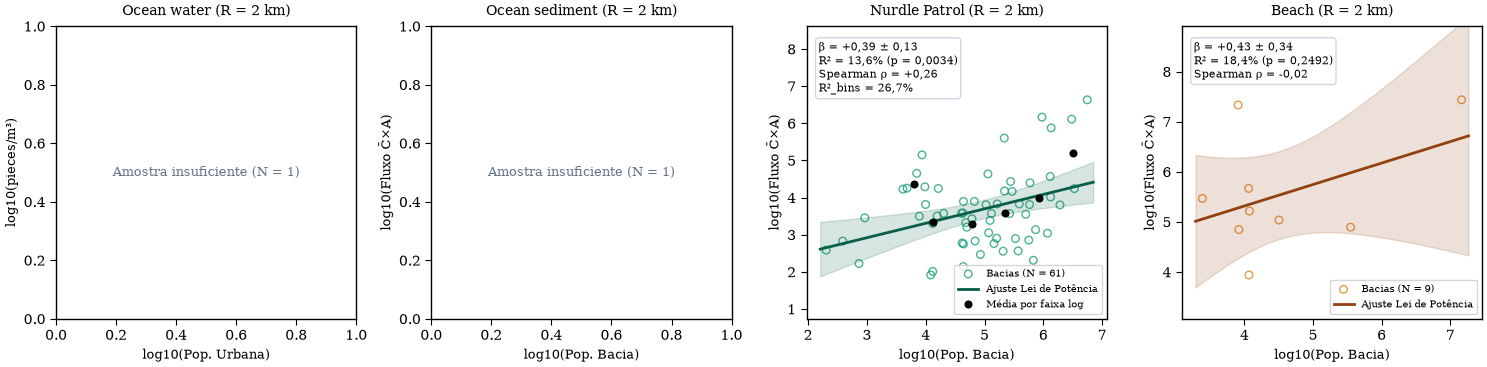

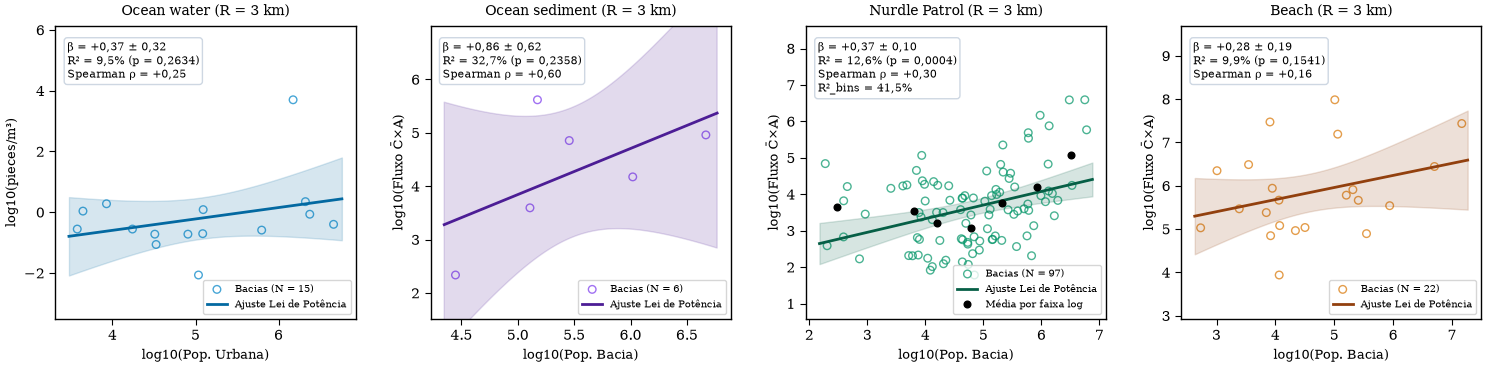

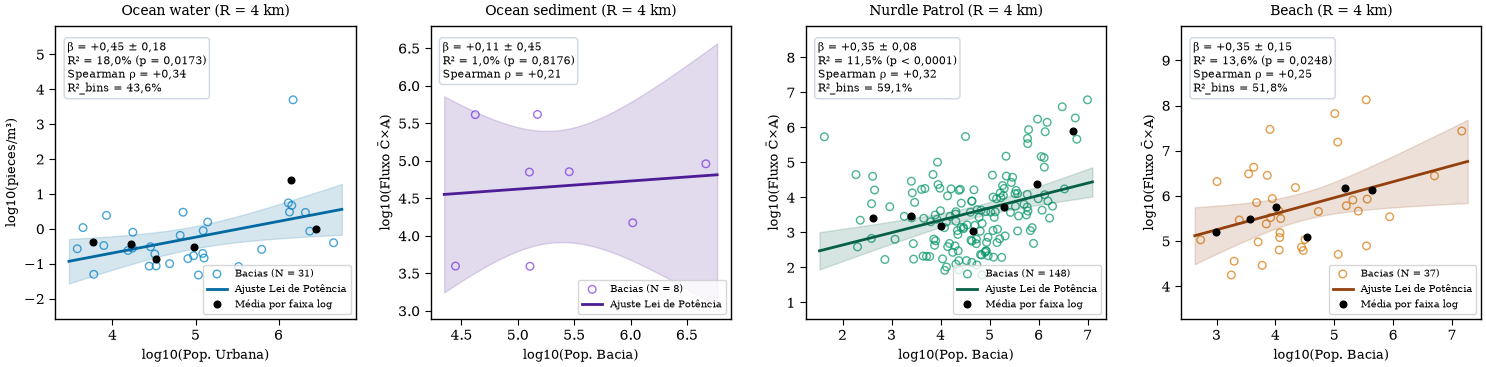

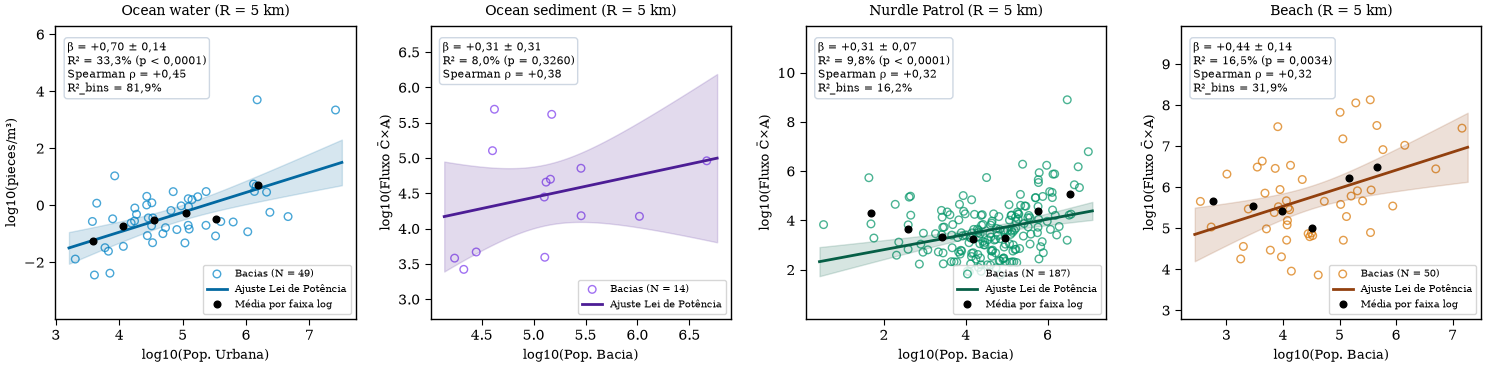

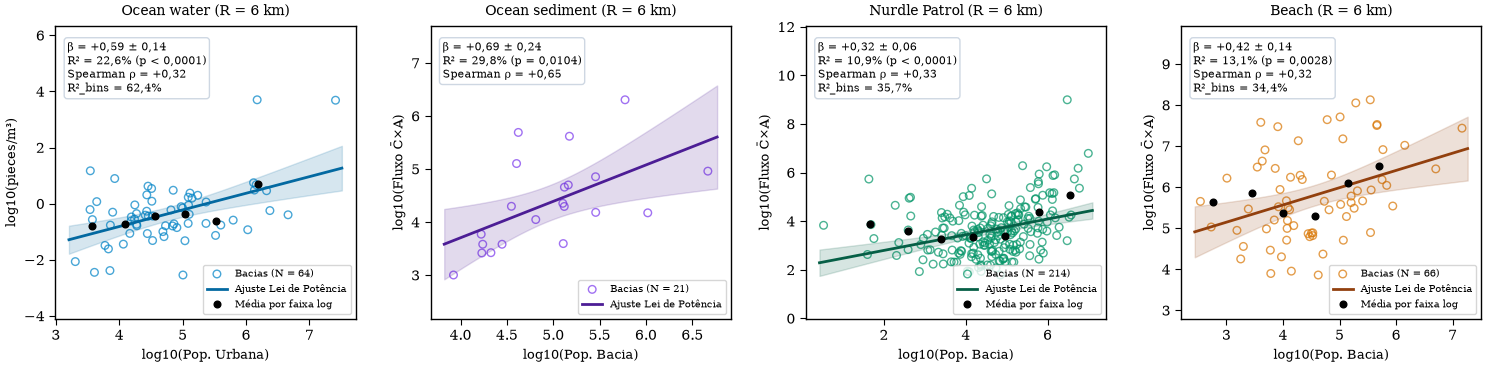

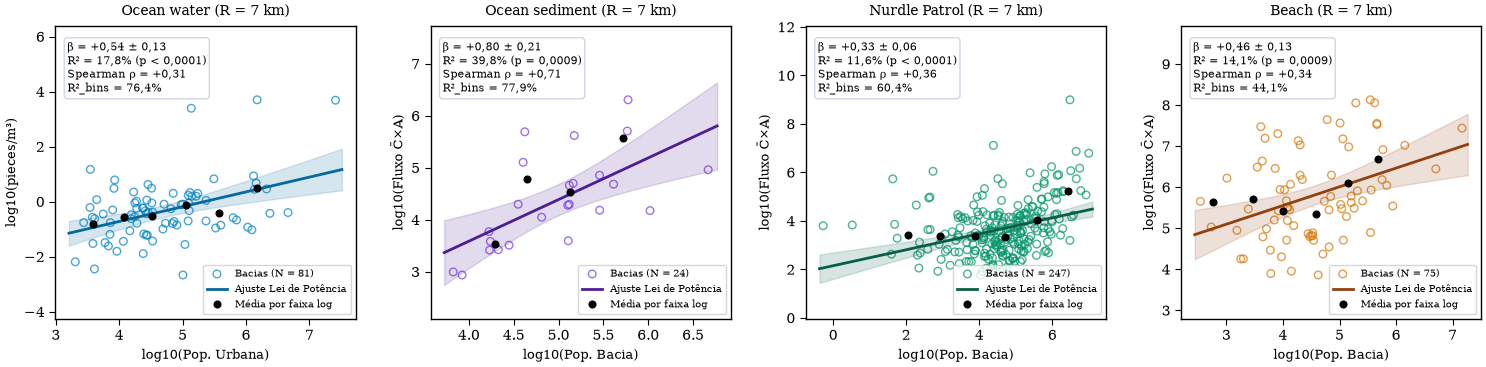

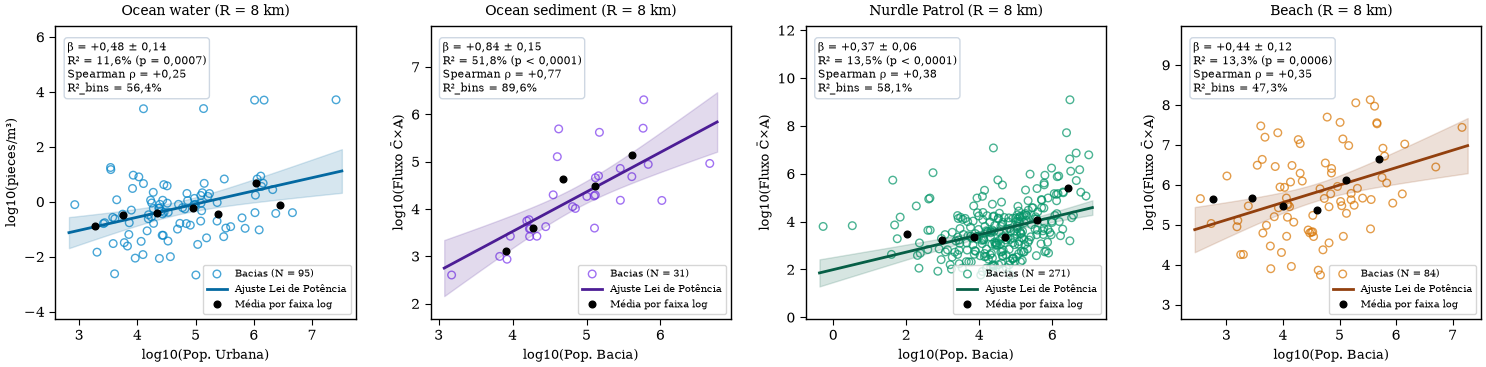

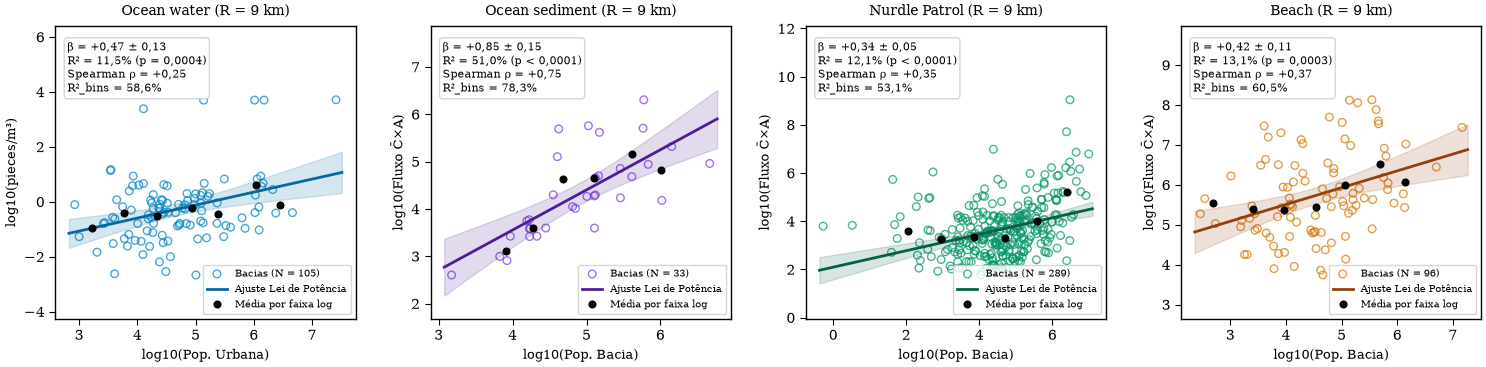

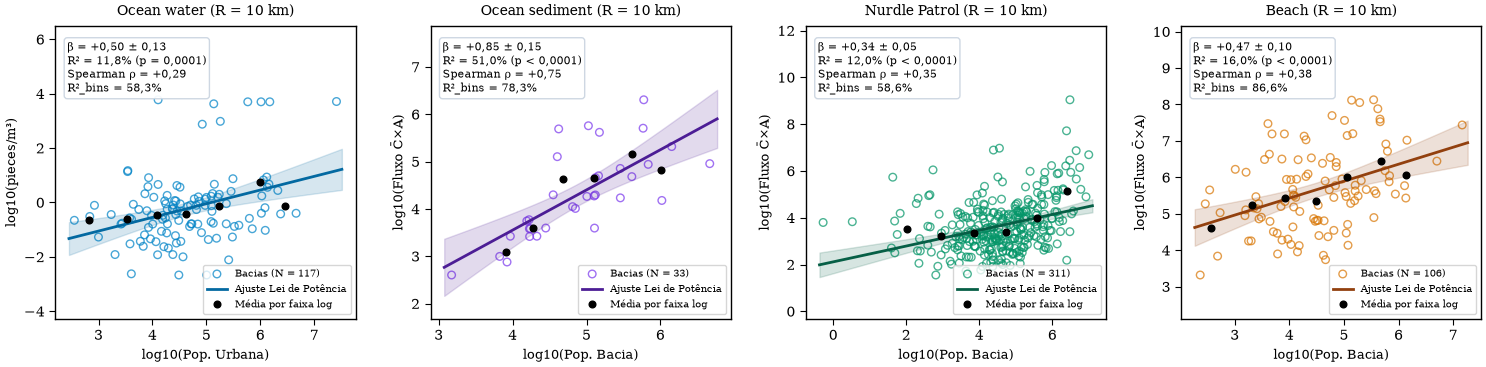

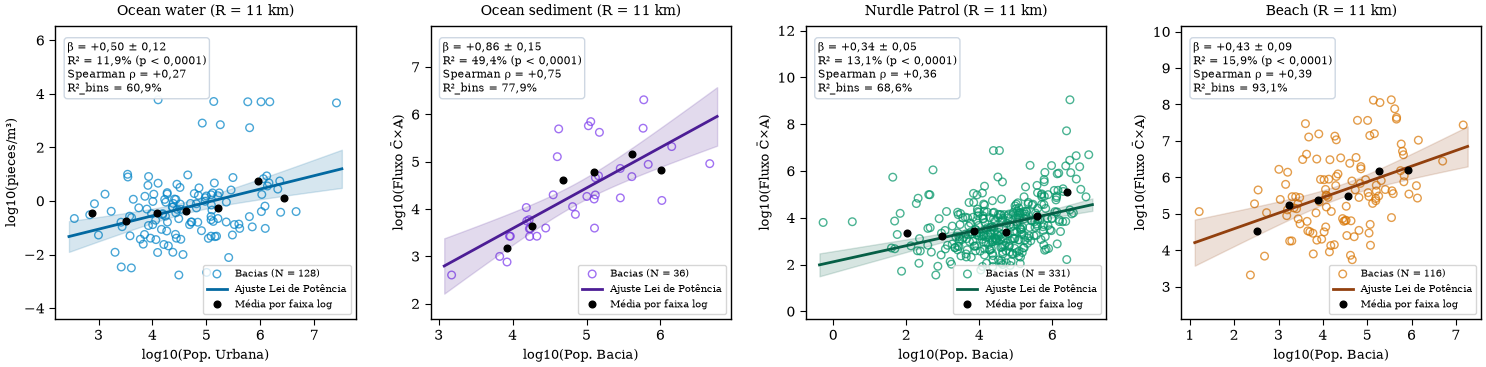

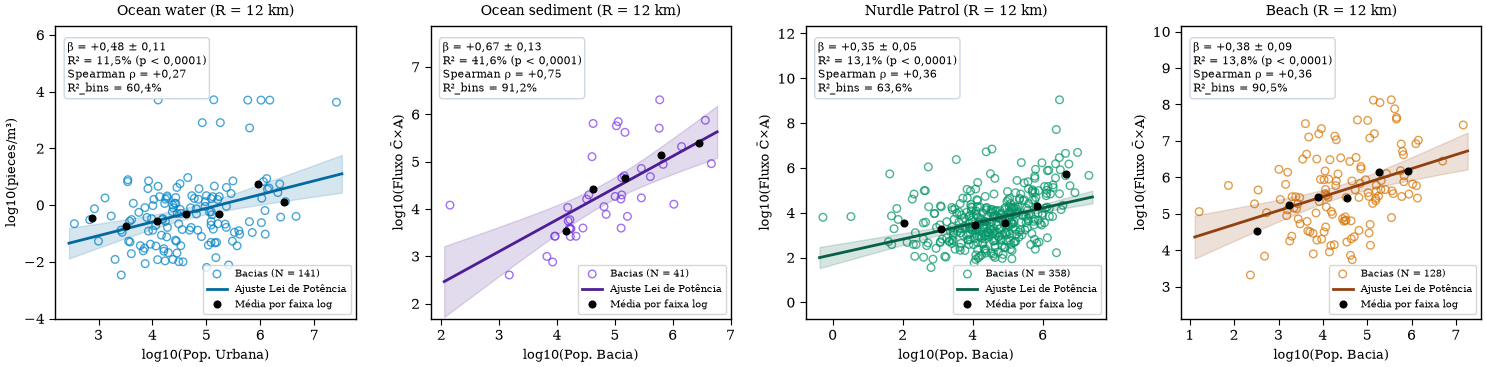

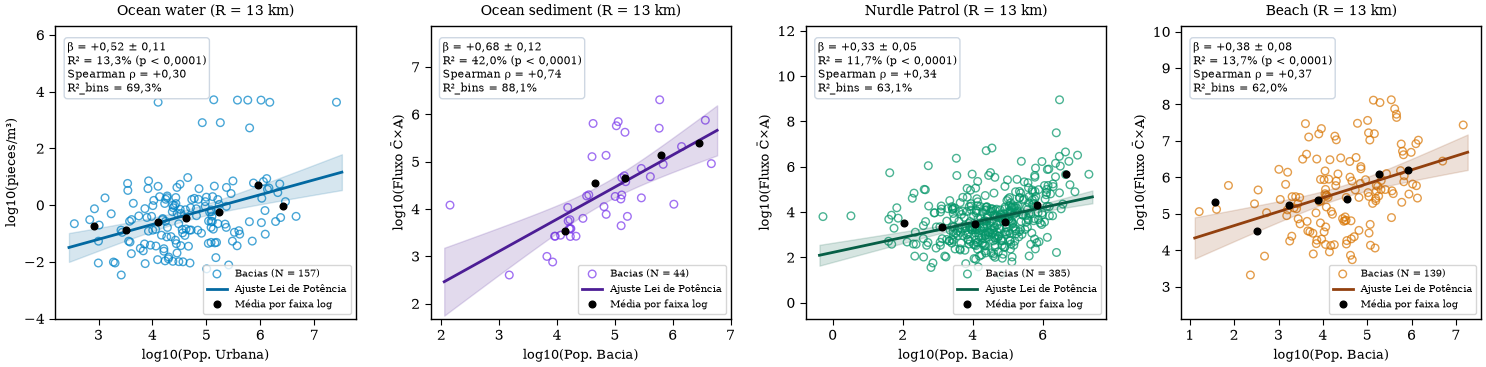

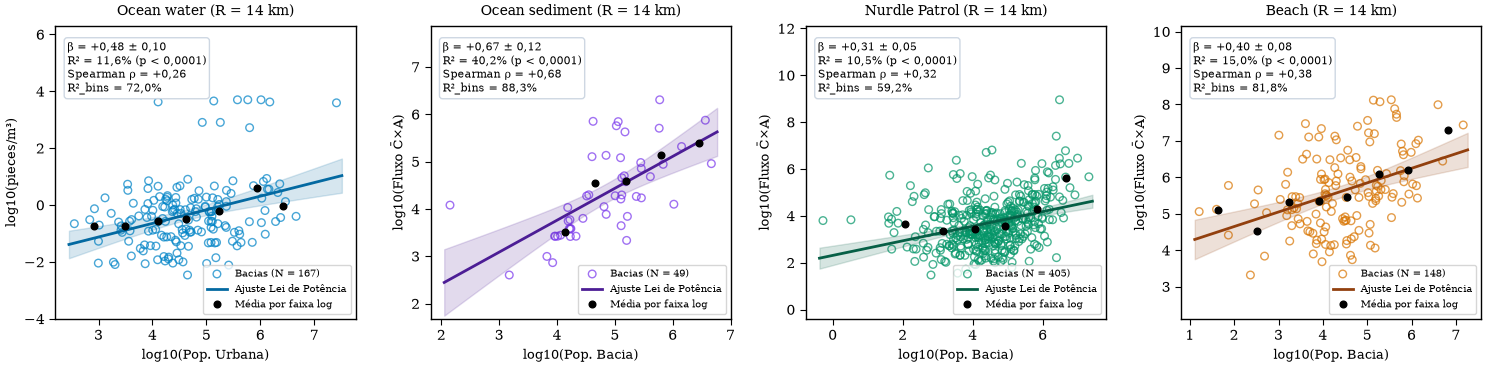

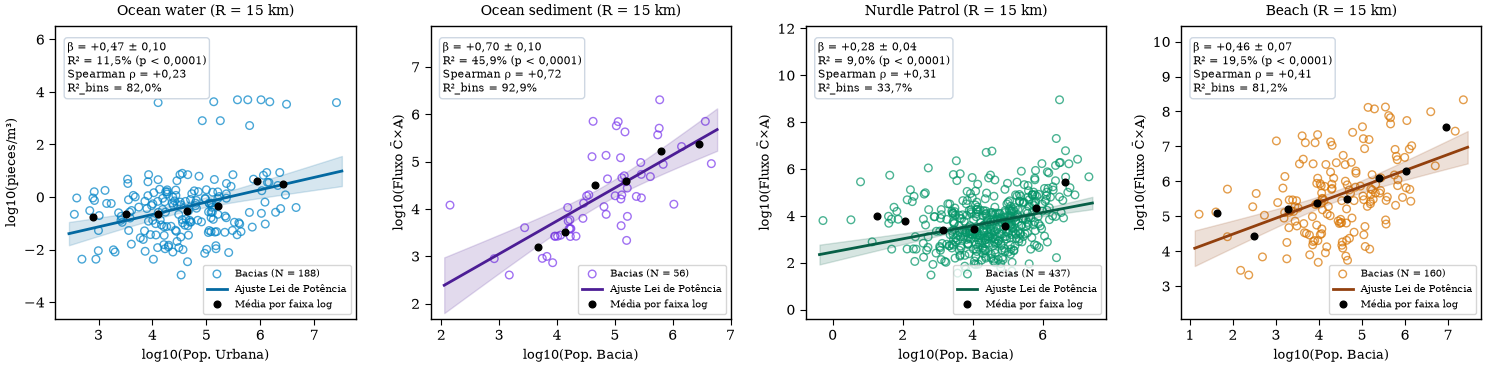

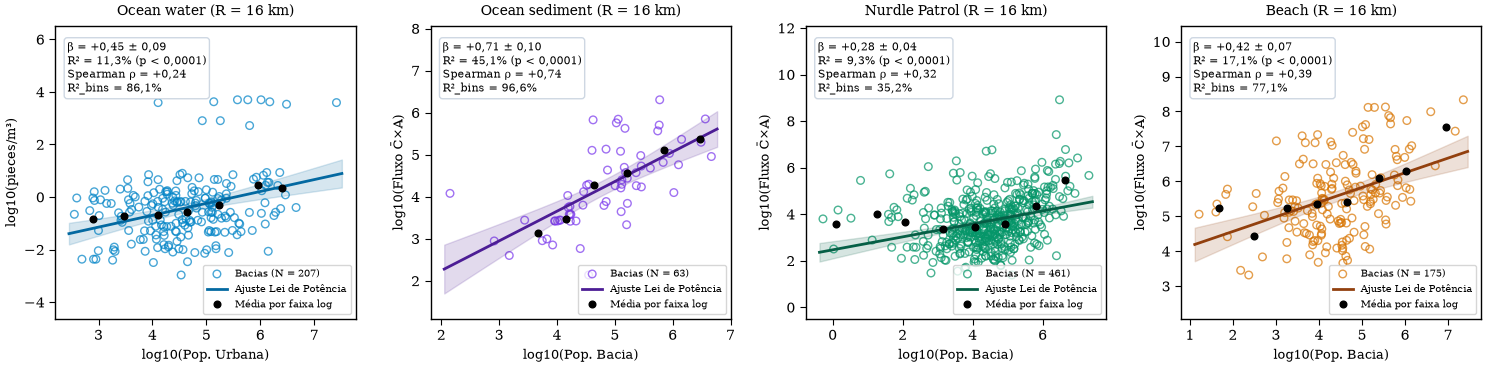

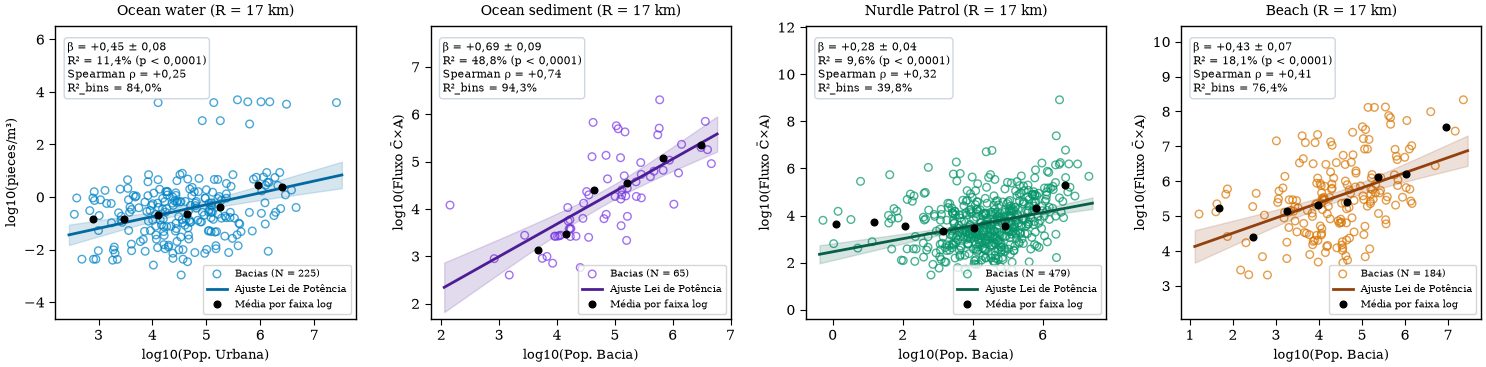

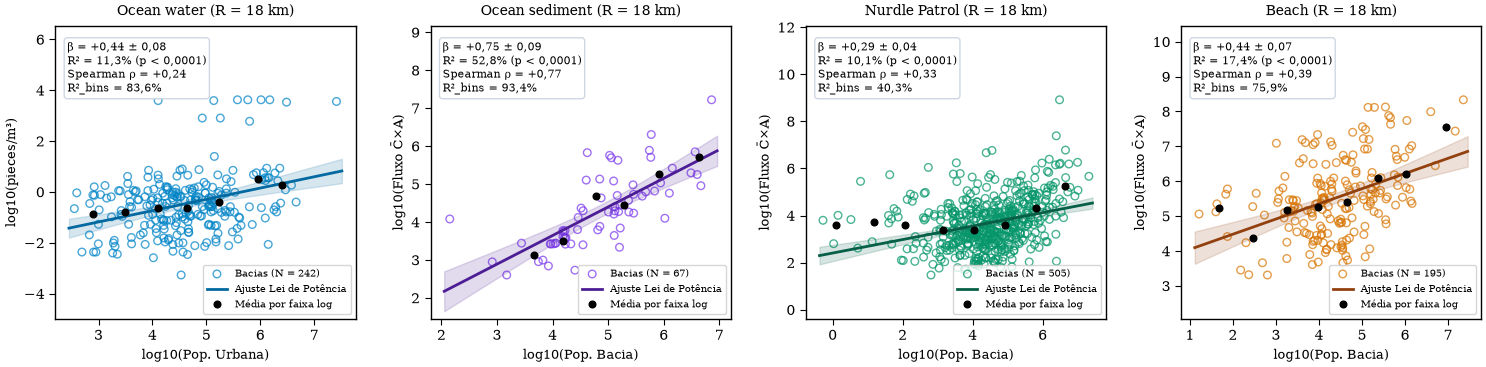

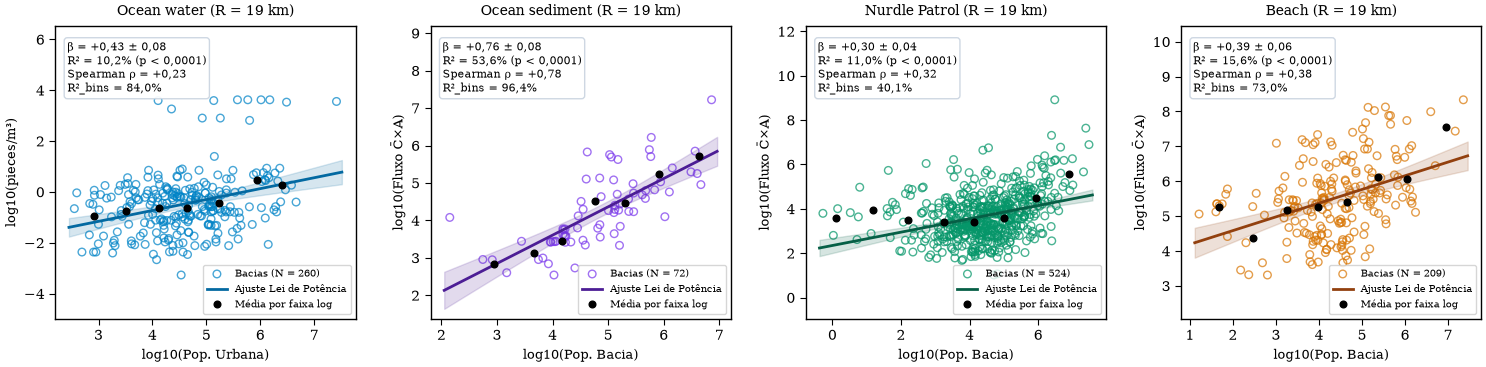

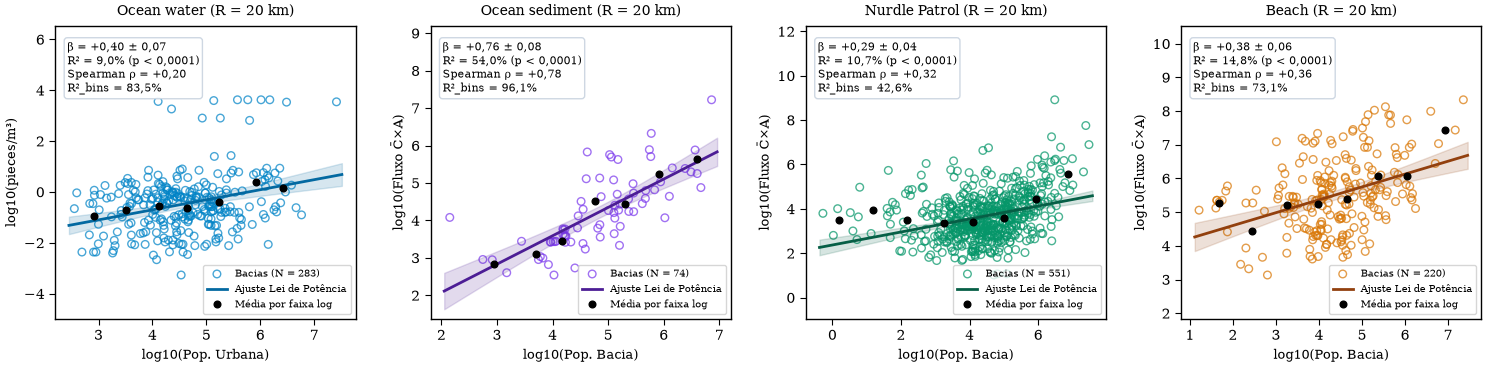

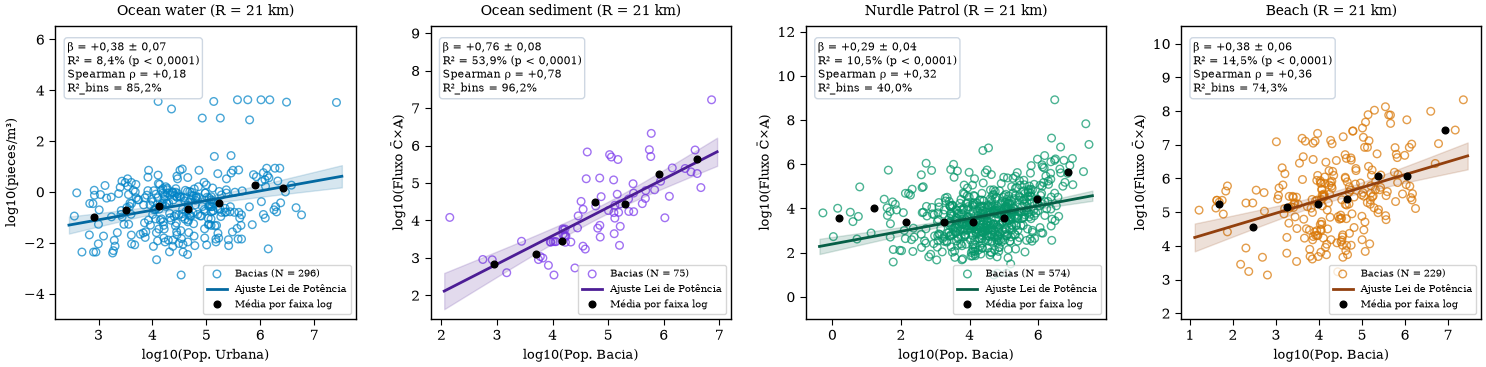

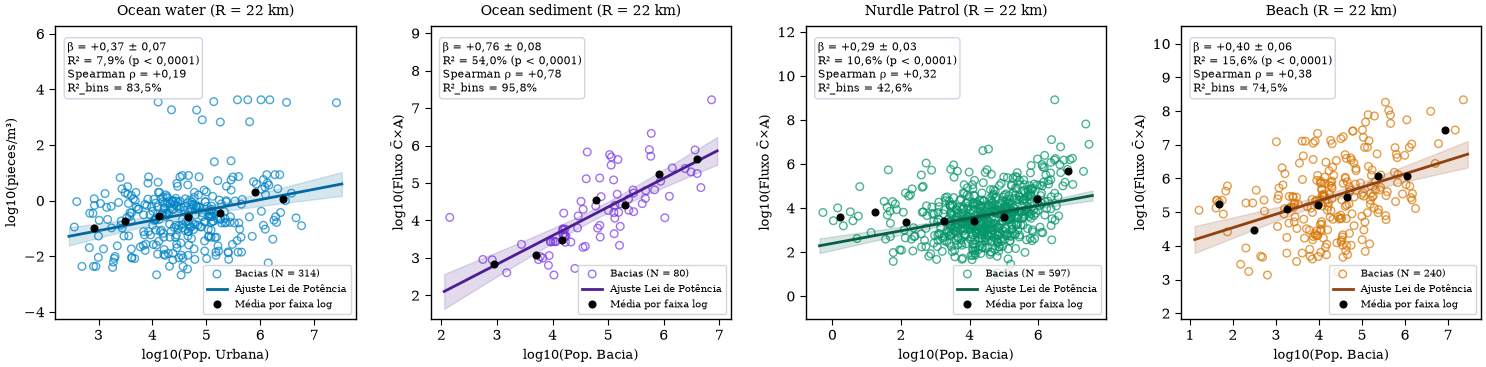

In [5]:
configs = [
    ("Ocean water", "urban_population", "mp_mean", "log10(Pop. Urbana)", "log10(pieces/m³)", "#0284c7", "#0369a1"),
    ("Ocean sediment", "total_population", "flux", "log10(Pop. Bacia)", "log10(Fluxo C̄×A)", "#7c3aed", "#4c1d95"),
    ("Nurdle Patrol", "total_population", "flux", "log10(Pop. Bacia)", "log10(Fluxo C̄×A)", "#059669", "#065f46"),
    ("Beach", "total_population", "flux", "log10(Pop. Bacia)", "log10(Fluxo C̄×A)", "#d97706", "#92400e"),
]

for r_km in range(1, 23):
    fig, axes = plt.subplots(1, 4, figsize=(18.4, 3.8), gridspec_kw={"wspace": 0.25})
    for ax, (nome, p_col, y_col, xl, yl, c_pt, c_ln) in zip(axes, configs):
        plotar_lei_potencia(ax, pareados_tipos_r[nome][r_km], p_col, y_col, f"{nome} (R = {r_km} km)", xl, yl, c_pt, c_ln)
    plt.show()